<a href="https://colab.research.google.com/github/mushWhoom/butterfly-image-classification-rnn/blob/main/RNN_MinProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import datetime

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image
from tensorflow import keras

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("phucthaiv02/butterfly-image-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'butterfly-image-classification' dataset.
Path to dataset files: /kaggle/input/butterfly-image-classification


In [ ]:
import os

path = "/kaggle/input/butterfly-image-classification"
print("Isi folder utama:", os.listdir(path))

# Biasanya akan terlihat folder train, test, dan file CSV
train_path = os.path.join(path, "train")
test_path = os.path.join(path, "test")

if os.path.exists(train_path):
    print("Contoh gambar di train:", os.listdir(train_path)[:5])

Isi folder utama: ['Training_set.csv', 'Testing_set.csv', 'test', 'train']
Contoh gambar di train: ['Image_4378.jpg', 'Image_5576.jpg', 'Image_6267.jpg', 'Image_747.jpg', 'Image_5775.jpg']


In [ ]:
import os
print("Isi /content/:")
for item in os.listdir('/content/'):
    print(' -', item)

Isi /content/:
 - .config
 - archive.zip
 - sample_data


In [ ]:
import zipfile
import os

zip_path = '/content/archive.zip'
extract_dir = '/content/dataset/'
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("Ekstrak selesai. Isi folder dataset:")
for root, dirs, files in os.walk(extract_dir):
    level = root.replace(extract_dir, '').count(os.sep)
    indent = ' ' * 2 * level
    print(f'{indent}{os.path.basename(root)}/')
    subindent = ' ' * 2 * (level + 1)
    for file in files[:5]:
        print(f'{subindent}{file}')
    if len(files) > 5:
        print(f'{subindent}... dan {len(files)-5} file lainnya')

Ekstrak selesai. Isi folder dataset:
/
  Training_set.csv
  Testing_set.csv
test/
  Image_1553.jpg
  Image_2125.jpg
  Image_1484.jpg
  Image_624.jpg
  Image_2642.jpg
  ... dan 2781 file lainnya
train/
  Image_3829.jpg
  Image_1553.jpg
  Image_3635.jpg
  Image_2936.jpg
  Image_5188.jpg
  ... dan 6494 file lainnya


In [ ]:
dataset_path = '/content/dataset/'
train_csv = os.path.join(dataset_path, 'Training_set.csv')
test_csv = os.path.join(dataset_path, 'Testing_set.csv')
train_img_dir = os.path.join(dataset_path, 'train')
test_img_dir = os.path.join(dataset_path, 'test')

In [ ]:
import pandas as pd

train_df = pd.read_csv(train_csv)
test_df = pd.read_csv(test_csv)

print("Train DataFrame shape:", train_df.shape)
print(train_df.head())

Train DataFrame shape: (6499, 2)
      filename                     label
0  Image_1.jpg          SOUTHERN DOGFACE
1  Image_2.jpg                    ADONIS
2  Image_3.jpg            BROWN SIPROETA
3  Image_4.jpg                   MONARCH
4  Image_5.jpg  GREEN CELLED CATTLEHEART


In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Parameter
img_width, img_height = 224, 224
batch_size = 32
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.2
)
valid_test_datagen = ImageDataGenerator(rescale=1./255)

In [ ]:
# Training generator
train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=train_img_dir,
    x_col='filename',
    y_col='label',
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    shuffle=True,
    seed=42
)

# Validation generator
valid_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=train_img_dir,
    x_col='filename',
    y_col='label',
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    shuffle=True,
    seed=42
)

# Mendapatkan mapping kelas (agar submission nanti pakai nama kelas asli)
class_indices = train_generator.class_indices
class_names = list(class_indices.keys())
print("Classes:", class_names)

Found 5200 validated image filenames belonging to 75 classes.
Found 1299 validated image filenames belonging to 75 classes.
Classes: ['ADONIS', 'AFRICAN GIANT SWALLOWTAIL', 'AMERICAN SNOOT', 'AN 88', 'APPOLLO', 'ATALA', 'BANDED ORANGE HELICONIAN', 'BANDED PEACOCK', 'BECKERS WHITE', 'BLACK HAIRSTREAK', 'BLUE MORPHO', 'BLUE SPOTTED CROW', 'BROWN SIPROETA', 'CABBAGE WHITE', 'CAIRNS BIRDWING', 'CHECQUERED SKIPPER', 'CHESTNUT', 'CLEOPATRA', 'CLODIUS PARNASSIAN', 'CLOUDED SULPHUR', 'COMMON BANDED AWL', 'COMMON WOOD-NYMPH', 'COPPER TAIL', 'CRECENT', 'CRIMSON PATCH', 'DANAID EGGFLY', 'EASTERN COMA', 'EASTERN DAPPLE WHITE', 'EASTERN PINE ELFIN', 'ELBOWED PIERROT', 'GOLD BANDED', 'GREAT EGGFLY', 'GREAT JAY', 'GREEN CELLED CATTLEHEART', 'GREY HAIRSTREAK', 'INDRA SWALLOW', 'IPHICLUS SISTER', 'JULIA', 'LARGE MARBLE', 'MALACHITE', 'MANGROVE SKIPPER', 'MESTRA', 'METALMARK', 'MILBERTS TORTOISESHELL', 'MONARCH', 'MOURNING CLOAK', 'ORANGE OAKLEAF', 'ORANGE TIP', 'ORCHARD SWALLOW', 'PAINTED LADY', 'PAPER

In [ ]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Load base model tanpa top, bobot ImageNet
base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(img_width, img_height, 3))

# Freeze base model (tidak latih dulu)
base_model.trainable = False

# Tambahkan head klasifikasi
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)
predictions = Dense(len(class_names), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)

model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,396,782 (16.77 MB)

 Trainable params: 347,211 (1.32 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
# Latih model menggunakan generator yang sudah dibuat
epochs = 10  # bisa disesuaikan

history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    validation_data=valid_generator,
    validation_steps=valid_generator.samples // batch_size,
    epochs=epochs
)

Epoch 1/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 239s 3s/step - accuracy: 0.0174 - loss: 4.3138 - val_accuracy: 0.0203 - val_loss: 4.3163
Epoch 2/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 244s 3s/step - accuracy: 0.0214 - loss: 4.3135 - val_accuracy: 0.0297 - val_loss: 4.3172
Epoch 3/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.0312 - loss: 4.3053 - val_accuracy: 0.0250 - val_loss: 4.3174
Epoch 4/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 261s 3s/step - accuracy: 0.0182 - loss: 4.3144 - val_accuracy: 0.0172 - val_loss: 4.3183
Epoch 5/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 263s 3s/step - accuracy: 0.0239 - loss: 4.3124 - val_accuracy: 0.0188 - val_loss: 4.3189
Epoch 6/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 50s 600ms/step - accuracy: 0.0000e+00 - loss: 4.3081 - val_accuracy: 0.0219 - val_loss: 4.3194
Epoch 7/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 261s 3s/step - accuracy: 0.0204 - loss: 4.3133 - val_accuracy: 0.0219 - val_loss: 4.3159
Epoch 8/10
81/81 ━━━━━━━━━━━━━━━━━━━━ 247s 3s/step - accuracy: 0.0190 - loss: 4.3139 - val_accuracy: 0.018

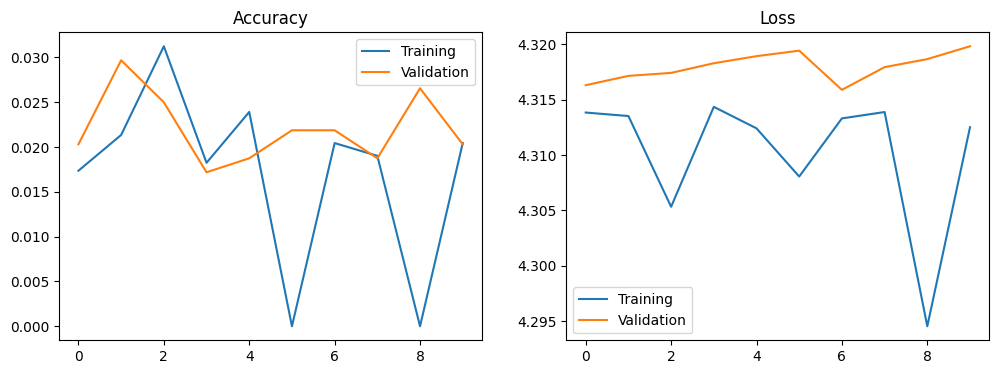

In [ ]:
import matplotlib.pyplot as plt

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(acc, label='Training')
plt.plot(val_acc, label='Validation')
plt.title('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(loss, label='Training')
plt.plot(val_loss, label='Validation')
plt.title('Loss')
plt.legend()
plt.show()

In [ ]:
best_acc = 0
best_lr = 0.001
for lr in [0.001, 0.0001]:
    model_tune = tf.keras.models.clone_model(model)
    model_tune.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                       loss='categorical_crossentropy',
                       metrics=['accuracy'])
    h = model_tune.fit(train_generator,
                       steps_per_epoch=train_generator.samples // batch_size,
                       validation_data=valid_generator,
                       validation_steps=valid_generator.samples // batch_size,
                       epochs=3, verbose=0)
    val = max(h.history['val_accuracy'])
    if val > best_acc:
        best_acc = val
        best_lr = lr
print(f"Learning rate terbaik: {best_lr} (val_acc: {best_acc:.4f})")

Learning rate terbaik: 0.001 (val_acc: 0.0219)


In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=best_lr),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history_final = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    validation_data=valid_generator,
    validation_steps=valid_generator.samples // batch_size,
    epochs=5
)

Epoch 1/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 255s 3s/step - accuracy: 0.0181 - loss: 4.3138 - val_accuracy: 0.0219 - val_loss: 4.3147
Epoch 2/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 261s 3s/step - accuracy: 0.0186 - loss: 4.3143 - val_accuracy: 0.0250 - val_loss: 4.3145
Epoch 3/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.0625 - loss: 4.2979 - val_accuracy: 0.0234 - val_loss: 4.3185
Epoch 4/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 274s 3s/step - accuracy: 0.0174 - loss: 4.3132 - val_accuracy: 0.0250 - val_loss: 4.3173
Epoch 5/5
81/81 ━━━━━━━━━━━━━━━━━━━━ 261s 3s/step - accuracy: 0.0202 - loss: 4.3131 - val_accuracy: 0.0234 - val_loss: 4.3172


In [ ]:
# Simpan
model.save('/content/butterfly_model.h5')
print("Model disimpan.")

# Muat kembali
loaded_model = tf.keras.models.load_model('/content/butterfly_model.h5')
print("Model dimuat kembali.")

# Uji konsistensi (bandingkan prediksi pada batch pertama dari valid_generator)
import numpy as np

# Ambil satu batch dari valid_generator
X_batch, y_batch = next(iter(valid_generator))

pred_orig = model.predict(X_batch)
pred_loaded = loaded_model.predict(X_batch)

Model disimpan.


Model dimuat kembali.
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


In [ ]:
# Test generator
test_generator = valid_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    directory=test_img_dir,
    x_col='filename',
    y_col=None,
    target_size=(img_width, img_height),
    batch_size=batch_size,
    class_mode=None,
    shuffle=False
)

# Prediksi
probs = model.predict(test_generator)
pred_class_idx = np.argmax(probs, axis=1)
pred_labels = [class_names[i] for i in pred_class_idx]

# Submission
submission = pd.DataFrame({'filename': test_df['filename'], 'label': pred_labels})
submission.to_csv('/content/submission.csv', index=False)
print("Submission.csv siap!")

Found 2786 validated image filenames.
44/44 ━━━━━━━━━━━━━━━━━━━━ 197s 4s/step
Submission.csv siap!


In [ ]:
from sklearn.metrics import classification_report
valid_generator.reset()
preds = model.predict(valid_generator, verbose=1)
y_pred = np.argmax(preds, axis=1)
y_true = valid_generator.classes
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

41/41 ━━━━━━━━━━━━━━━━━━━━ 105s 2s/step
                           precision    recall  f1-score   support

                   ADONIS       0.00      0.00      0.00        19
AFRICAN GIANT SWALLOWTAIL       0.00      0.00      0.00        17
           AMERICAN SNOOT       0.00      0.00      0.00        16
                    AN 88       0.00      0.00      0.00        17
                  APPOLLO       0.00      0.00      0.00        14
                    ATALA       0.00      0.00      0.00        23
 BANDED ORANGE HELICONIAN       0.00      0.00      0.00        19
           BANDED PEACOCK       0.00      0.00      0.00        16
            BECKERS WHITE       0.00      0.00      0.00        16
         BLACK HAIRSTREAK       0.00      0.00      0.00        27
              BLUE MORPHO       0.00      0.00      0.00        10
        BLUE SPOTTED CROW       0.00      0.00      0.00        16
           BROWN SIPROETA       0.00      0.00      0.00        26
            CABBAGE W

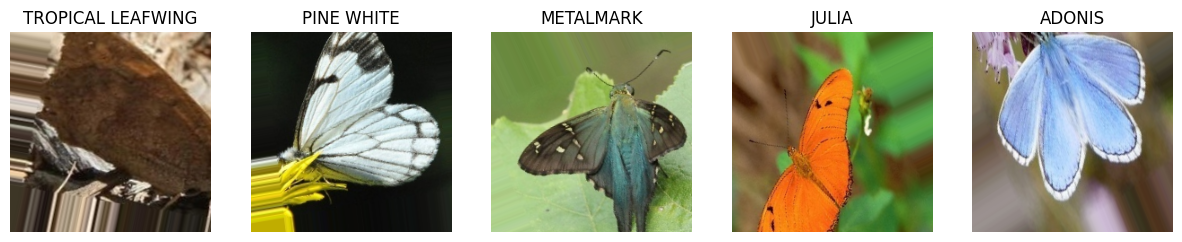

In [ ]:
#contoh gambar sample
import matplotlib.pyplot as plt
images, labels = next(train_generator)
plt.figure(figsize=(15, 8))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(images[i])
    plt.title(class_names[np.argmax(labels[i])])
    plt.axis('off')
plt.show()